### Name: Albatul Altoum



Initial Predictions BEFORE Training:
Input: [0. 0.] | Predicted: 0.3847 | Expected: 0.0
Input: [0. 1.] | Predicted: 0.7636 | Expected: 1.0
Input: [1. 0.] | Predicted: 0.4863 | Expected: 1.0
Input: [1. 1.] | Predicted: 0.8642 | Expected: 0.0
Epoch    0 | Loss: 0.8683 | Accuracy: 50.00%
Epoch  500 | Loss: 0.1204 | Accuracy: 100.00%
Epoch 1000 | Loss: 0.0663 | Accuracy: 100.00%
Epoch 1500 | Loss: 0.0490 | Accuracy: 100.00%
Epoch 2000 | Loss: 0.0401 | Accuracy: 100.00%
Epoch 2500 | Loss: 0.0346 | Accuracy: 100.00%
Epoch 3000 | Loss: 0.0308 | Accuracy: 100.00%
Epoch 3500 | Loss: 0.0279 | Accuracy: 100.00%
Epoch 4000 | Loss: 0.0257 | Accuracy: 100.00%
Epoch 4500 | Loss: 0.0239 | Accuracy: 100.00%

Final Predictions AFTER Training:
Input: [0. 0.] | Predicted: 0.0291 | Expected: 0.0
Input: [0. 1.] | Predicted: 0.9848 | Expected: 1.0
Input: [1. 0.] | Predicted: 0.9848 | Expected: 1.0
Input: [1. 1.] | Predicted: 0.0291 | Expected: 0.0


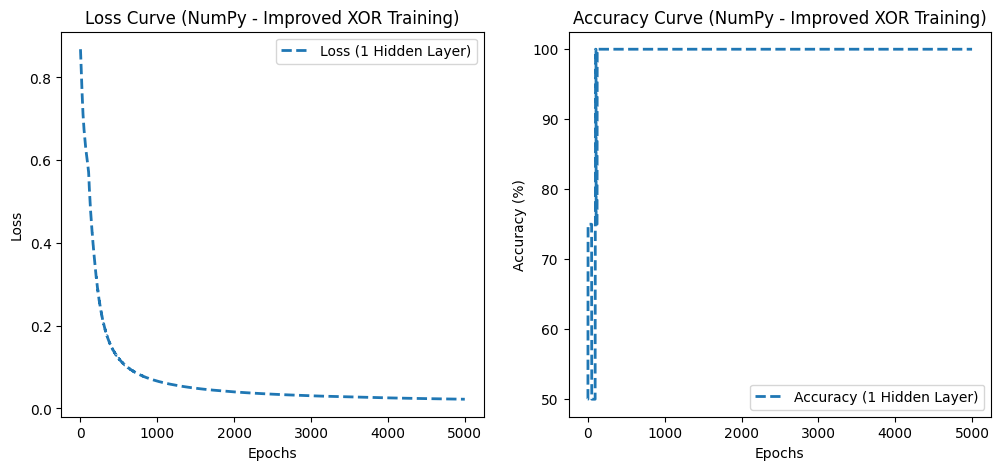

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------- Data Preparation --------------------
X_numpy = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=np.float32)
y_numpy = np.array([[0], [1], [1], [0]], dtype=np.float32)

# Use all four cases for training (No test split)
X_train, y_train = X_numpy, y_numpy

# -------------------- Neural Network with One Hidden Layer(No Momentum, No Batch Normalization) --------------------
class ImprovedNumPyNN:
    def __init__(self):
        np.random.seed(42)
        # Initialize weights and biases for input -> hidden layer (2 neurons)
        self.weights_input_hidden = np.random.randn(2, 2)
        self.bias_hidden = np.random.randn(1, 2)

        # Initialize weights and biases for hidden -> output layer (1 neuron)
        self.weights_hidden_output = np.random.randn(2, 1)
        self.bias_output = np.random.randn(1)

    def sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    def relu(self, x):
        return np.maximum(0, x)  # ReLU activation function

    def predict(self, X):
        # Forward pass through hidden layer
        hidden_input = np.dot(X, self.weights_input_hidden) + self.bias_hidden
        hidden_output = self.relu(hidden_input)

        # Forward pass through output layer
        final_input = np.dot(hidden_output, self.weights_hidden_output) + self.bias_output
        final_output = self.sigmoid(final_input)
        return final_output

    def train(self, X, y, lr=0.1, epochs=5000):
        loss_log, accuracy_log = [], []

        for epoch in range(epochs):
            # Forward pass
            hidden_input = np.dot(X, self.weights_input_hidden) + self.bias_hidden
            hidden_output = self.relu(hidden_input)
            final_input = np.dot(hidden_output, self.weights_hidden_output) + self.bias_output
            output = self.sigmoid(final_input)

            # Compute loss using Binary Cross Entropy
            loss = -np.mean(y * np.log(output + 1e-8) + (1 - y) * np.log(1 - output + 1e-8))

            # Compute gradients (Backward Propagation)
            d_output = (output - y) * output * (1 - output)  # Derivative of sigmoid loss
            grad_w_hidden_output = np.dot(hidden_output.T, d_output)
            grad_b_output = np.sum(d_output, axis=0, keepdims=True)

            d_hidden = np.dot(d_output, self.weights_hidden_output.T)
            d_hidden[hidden_output <= 0] = 0  # Derivative of ReLU (Only pass gradients if > 0)

            grad_w_input_hidden = np.dot(X.T, d_hidden)
            grad_b_hidden = np.sum(d_hidden, axis=0, keepdims=True)

            # Update weights and biases
            self.weights_hidden_output -= lr * grad_w_hidden_output
            self.bias_output -= lr * grad_b_output.squeeze()

            self.weights_input_hidden -= lr * grad_w_input_hidden
            self.bias_hidden -= lr * grad_b_hidden

            # Compute accuracy
            accuracy = np.mean((output > 0.5) == y) * 100
            loss_log.append(loss)
            accuracy_log.append(accuracy)

            # Print loss and accuracy every 500 epochs
            if epoch % 500 == 0:
                print(f"Epoch {epoch:4d} | Loss: {loss:.4f} | Accuracy: {accuracy:.2f}%")

        return loss_log, accuracy_log

# -------------------- Display Initial Predictions Before Training --------------------
numpy_nn = ImprovedNumPyNN()
initial_predictions = numpy_nn.predict(X_train)
print("\nInitial Predictions BEFORE Training:")
for i in range(len(X_train)):
    print(f"Input: {X_train[i]} | Predicted: {initial_predictions[i][0]:.4f} | Expected: {y_train[i][0]}")

# -------------------- Train the Model --------------------
loss_numpy, acc_numpy = numpy_nn.train(X_train, y_train, lr=0.1, epochs=5000)

# -------------------- Display Predictions After Training --------------------
final_predictions = numpy_nn.predict(X_train)
print("\nFinal Predictions AFTER Training:")
for i in range(len(X_train)):
    print(f"Input: {X_train[i]} | Predicted: {final_predictions[i][0]:.4f} | Expected: {y_train[i][0]}")
    # -------------------- Plot the Results --------------------
plt.figure(figsize=(12, 5))

# Loss curve
plt.subplot(1, 2, 1)
plt.plot(loss_numpy, label="Loss (1 Hidden Layer)", linestyle="--", linewidth=2)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss Curve (NumPy - Improved XOR Training)")
plt.legend()

# Accuracy curve
plt.subplot(1, 2, 2)
plt.plot(acc_numpy, label="Accuracy (1 Hidden Layer)", linestyle="--", linewidth=2)
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy Curve (NumPy - Improved XOR Training)")
plt.legend()

plt.show()


Initial Predictions BEFORE Training:
Input: [0. 0.] | Predicted: 0.4707 | Expected: 0.0
Input: [0. 1.] | Predicted: 0.7790 | Expected: 1.0
Input: [1. 0.] | Predicted: 0.0359 | Expected: 1.0
Input: [1. 1.] | Predicted: 0.3507 | Expected: 0.0

Starting Training...

Epoch     0 | Loss: 1.1610 | Accuracy: 75.00%
Epoch  1000 | Loss: 0.0503 | Accuracy: 100.00%
Epoch  2000 | Loss: 0.0326 | Accuracy: 100.00%
Epoch  3000 | Loss: 0.0257 | Accuracy: 100.00%
Epoch  4000 | Loss: 0.0217 | Accuracy: 100.00%
Epoch  5000 | Loss: 0.0192 | Accuracy: 100.00%
Epoch  6000 | Loss: 0.0173 | Accuracy: 100.00%
Epoch  7000 | Loss: 0.0159 | Accuracy: 100.00%
Epoch  8000 | Loss: 0.0148 | Accuracy: 100.00%
Epoch  9000 | Loss: 0.0138 | Accuracy: 100.00%

Final Predictions AFTER Training:
Input: [0. 0.] | Predicted: 0.0145 | Expected: 0.0
Input: [0. 1.] | Predicted: 0.9868 | Expected: 1.0
Input: [1. 0.] | Predicted: 0.9903 | Expected: 1.0
Input: [1. 1.] | Predicted: 0.0145 | Expected: 0.0


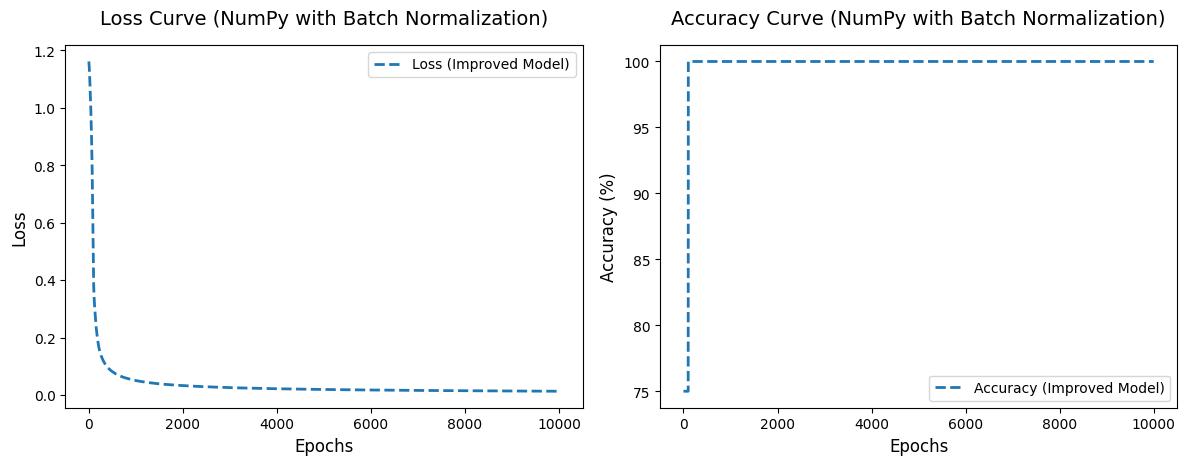


Final Training Accuracy: 100.00%


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------- Data Preparation --------------------
X_numpy = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=np.float32)
y_numpy = np.array([[0], [1], [1], [0]], dtype=np.float32)

X_train, y_train = X_numpy, y_numpy  # Use all samples for training

# -------------------- Improved Neural Network with Batch Normalization --------------------
class ImprovedNumPyNN_BatchNorm:
    def __init__(self, momentum_beta=0.9):
        np.random.seed(42)

        # Increase hidden layer neurons to 8
        self.weights_input_hidden = np.random.randn(2, 8) * np.sqrt(2 / 2)
        self.bias_hidden = np.zeros((1, 8))

        self.weights_hidden_output = np.random.randn(8, 1) * np.sqrt(2 / 8)
        self.bias_output = np.zeros((1, 1))

        # Momentum variables
        self.momentum_w_hidden = np.zeros_like(self.weights_input_hidden)
        self.momentum_b_hidden = np.zeros_like(self.bias_hidden)
        self.momentum_w_output = np.zeros_like(self.weights_hidden_output)
        self.momentum_b_output = np.zeros_like(self.bias_output)
        self.momentum_beta = momentum_beta  # Momentum coefficient

        # Batch Normalization Parameters
        self.gamma_hidden = np.ones((1, 8))
        self.beta_hidden = np.zeros((1, 8))
        self.epsilon = 1e-8  # Small value to prevent division by zero

    def sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    def leaky_relu(self, x, alpha=0.01):
        return np.where(x > 0, x, alpha * x)

    def batch_norm_forward(self, X):
        """ Apply Batch Normalization during the forward pass """
        self.mu = np.mean(X, axis=0, keepdims=True)
        self.var = np.var(X, axis=0, keepdims=True)
        X_norm = (X - self.mu) / np.sqrt(self.var + self.epsilon)  # Normalize
        return self.gamma_hidden * X_norm + self.beta_hidden  # Scale and shift

    def predict(self, X):
        """ Forward pass for predictions """
        hidden_input = np.dot(X, self.weights_input_hidden) + self.bias_hidden
        hidden_norm = self.batch_norm_forward(hidden_input)
        hidden_output = self.leaky_relu(hidden_norm)

        final_input = np.dot(hidden_output, self.weights_hidden_output) + self.bias_output
        final_output = self.sigmoid(final_input)
        return final_output

    def train(self, X, y, lr=0.1, epochs=10000):
        loss_log, accuracy_log = [], []

        # -------------------- Initial Predictions BEFORE Training --------------------
        initial_predictions = self.predict(X_train)
        print("\nInitial Predictions BEFORE Training:")
        for i in range(len(X_train)):
            print(f"Input: {X_train[i]} | Predicted: {initial_predictions[i][0]:.4f} | Expected: {y_train[i][0]}")

        print("\nStarting Training...\n")

        for epoch in range(epochs):
            # Forward pass
            hidden_input = np.dot(X, self.weights_input_hidden) + self.bias_hidden
            hidden_norm = self.batch_norm_forward(hidden_input)
            hidden_output = self.leaky_relu(hidden_norm)

            final_input = np.dot(hidden_output, self.weights_hidden_output) + self.bias_output
            output = self.sigmoid(final_input)

            # Compute loss using Binary Cross Entropy
            loss = -np.mean(y * np.log(output + self.epsilon) + (1 - y) * np.log(1 - output + self.epsilon))

            # Compute gradients (Backward Propagation)
            d_output = (output - y) * output * (1 - output)  # Derivative of sigmoid loss
            grad_w_hidden_output = np.dot(hidden_output.T, d_output)
            grad_b_output = np.sum(d_output, axis=0, keepdims=True)

            d_hidden = np.dot(d_output, self.weights_hidden_output.T)
            d_hidden[hidden_output <= 0] *= 0.01  # Derivative of Leaky ReLU

            grad_w_input_hidden = np.dot(X.T, d_hidden)
            grad_b_hidden = np.sum(d_hidden, axis=0, keepdims=True)

            # Apply SGD + Momentum
            self.momentum_w_output = self.momentum_beta * self.momentum_w_output + (1 - self.momentum_beta) * grad_w_hidden_output
            self.momentum_b_output = self.momentum_beta * self.momentum_b_output + (1 - self.momentum_beta) * grad_b_output

            self.momentum_w_hidden = self.momentum_beta * self.momentum_w_hidden + (1 - self.momentum_beta) * grad_w_input_hidden
            self.momentum_b_hidden = self.momentum_beta * self.momentum_b_hidden + (1 - self.momentum_beta) * grad_b_hidden

            # Update weights and biases
            self.weights_hidden_output -= lr * self.momentum_w_output
            self.bias_output -= lr * self.momentum_b_output

            self.weights_input_hidden -= lr * self.momentum_w_hidden
            self.bias_hidden -= lr * self.momentum_b_hidden

            # Compute accuracy
            accuracy = np.mean((output > 0.5) == y) * 100
            loss_log.append(loss)
            accuracy_log.append(accuracy)

            # Print progress every 1000 epochs
            if epoch % 1000 == 0:
                print(f"Epoch {epoch:5d} | Loss: {loss:.4f} | Accuracy: {accuracy:.2f}%")

        return loss_log, accuracy_log

# -------------------- Train the Model --------------------
nn_improved = ImprovedNumPyNN_BatchNorm()
loss_improved, acc_improved = nn_improved.train(X_train, y_train)

# -------------------- Display Final Predictions --------------------
final_predictions = nn_improved.predict(X_train)
print("\nFinal Predictions AFTER Training:")
for i in range(len(X_train)):
    print(f"Input: {X_train[i]} | Predicted: {final_predictions[i][0]:.4f} | Expected: {y_train[i][0]}")

# -------------------- Plot the Results --------------------
plt.figure(figsize=(12, 5))

# Loss curve
plt.subplot(1, 2, 1)
plt.plot(loss_improved, label="Loss (Improved Model)", linestyle="--", linewidth=2)
plt.xlabel("Epochs", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.title("Loss Curve (NumPy with Batch Normalization)", fontsize=14, pad=15)
plt.legend()

# Accuracy curve
plt.subplot(1, 2, 2)
plt.plot(acc_improved, label="Accuracy (Improved Model)", linestyle="--", linewidth=2)
plt.xlabel("Epochs", fontsize=12)
plt.ylabel("Accuracy (%)", fontsize=12)
plt.title("Accuracy Curve (NumPy with Batch Normalization)", fontsize=14, pad=15)
plt.legend()

# Adjust layout to prevent overlapping
plt.tight_layout()  # Automatically adjusts layout
plt.subplots_adjust(top=0.85)  # Increase spacing at the top

plt.show()

# Display final accuracy
print(f"\nFinal Training Accuracy: {acc_improved[-1]:.2f}%")


Initial Predictions BEFORE Training:
Input: [0. 0.] | Predicted: 0.5851 | Expected: 0.0
Input: [0. 1.] | Predicted: 0.6310 | Expected: 1.0
Input: [1. 0.] | Predicted: 0.4312 | Expected: 1.0
Input: [1. 1.] | Predicted: 0.5221 | Expected: 0.0
Epoch     0 | Loss: 0.7299 | Accuracy: 25.00%
Epoch   500 | Loss: 0.0025 | Accuracy: 100.00%
Epoch  1000 | Loss: 0.0012 | Accuracy: 100.00%
Epoch  1500 | Loss: 0.0008 | Accuracy: 100.00%
Epoch  2000 | Loss: 0.0006 | Accuracy: 100.00%
Epoch  2500 | Loss: 0.0005 | Accuracy: 100.00%
Epoch  3000 | Loss: 0.0004 | Accuracy: 100.00%
Epoch  3500 | Loss: 0.0003 | Accuracy: 100.00%
Epoch  4000 | Loss: 0.0003 | Accuracy: 100.00%
Epoch  4500 | Loss: 0.0003 | Accuracy: 100.00%

Final Predictions AFTER Training:
Input: [0. 0.] | Predicted: 0.0009 | Expected: 0.0
Input: [0. 1.] | Predicted: 1.0000 | Expected: 1.0
Input: [1. 0.] | Predicted: 1.0000 | Expected: 1.0
Input: [1. 1.] | Predicted: 0.0000 | Expected: 0.0


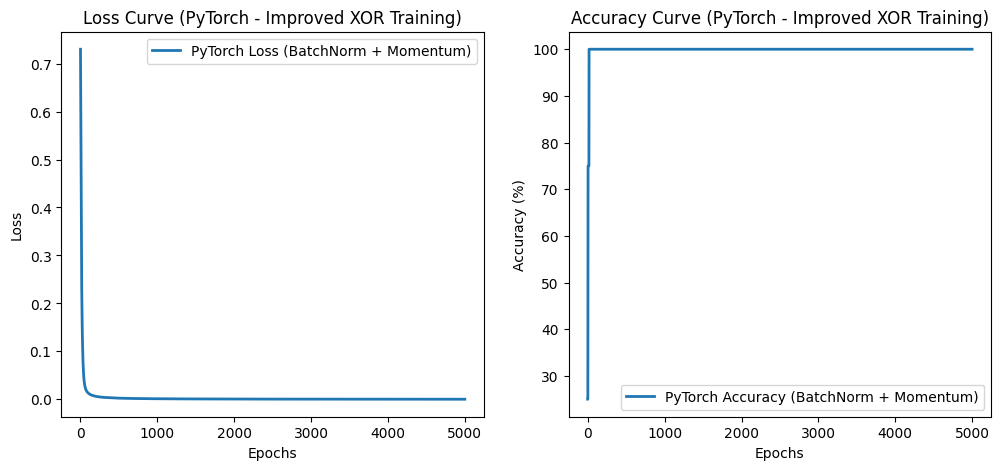

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F

# -------------------- Data Preparation --------------------
X_numpy = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=np.float32)
y_numpy = np.array([[0], [1], [1], [0]], dtype=np.float32)

# Convert to PyTorch tensors (All samples used for training)
X_train_torch = torch.tensor(X_numpy, dtype=torch.float32)
y_train_torch = torch.tensor(y_numpy, dtype=torch.float32)

# -------------------- Improved Neural Network Model --------------------
class ImprovedTorchNN(nn.Module):
    def __init__(self):
        super(ImprovedTorchNN, self).__init__()

        # Input to Hidden Layer (8 neurons)
        self.fc1 = nn.Linear(2, 8)
        self.bn1 = nn.BatchNorm1d(8)  # Batch Normalization for stability

        # Hidden Layer to Output
        self.fc2 = nn.Linear(8, 1)


    def forward(self, x):
        x = self.fc1(x)
        x = self.bn1(x)  # Apply Batch Normalization
        x = F.leaky_relu(x)  # Leaky ReLU activation using functional API
        x = torch.sigmoid(self.fc2(x))  # Final sigmoid activation for binary output
        return x

# Create model
torch_nn = ImprovedTorchNN()

# Use Binary Cross Entropy Loss
criterion = nn.BCELoss()

# Use SGD with Momentum for better convergence
optimizer = optim.SGD(torch_nn.parameters(), lr=0.1, momentum=0.9)

# -------------------- Initial Predictions Before Training --------------------
with torch.no_grad():
    initial_predictions = torch_nn(X_train_torch).numpy()

print("\nInitial Predictions BEFORE Training:")
for i in range(len(X_numpy)):
    print(f"Input: {X_numpy[i]} | Predicted: {initial_predictions[i][0]:.4f} | Expected: {y_numpy[i][0]}")

# -------------------- Training the Model --------------------
loss_torch, acc_torch = [], []

for epoch in range(5000):
    optimizer.zero_grad()
    output = torch_nn(X_train_torch)
    loss = criterion(output, y_train_torch)
    loss.backward()
    optimizer.step()

    # Compute accuracy
    accuracy = ((output.detach().numpy() > 0.5) == y_numpy).mean() * 100
    loss_torch.append(loss.item())
    acc_torch.append(accuracy)

    # Print loss and accuracy every 500 epochs
    if epoch % 500 == 0:
        print(f"Epoch {epoch:5d} | Loss: {loss.item():.4f} | Accuracy: {accuracy:.2f}%")

# -------------------- Final Predictions After Training --------------------
with torch.no_grad():
    final_predictions = torch_nn(X_train_torch).numpy()

print("\nFinal Predictions AFTER Training:")
for i in range(len(X_numpy)):
    print(f"Input: {X_numpy[i]} | Predicted: {final_predictions[i][0]:.4f} | Expected: {y_numpy[i][0]}")

# -------------------- Plot the Results --------------------
plt.figure(figsize=(12, 5))

# Loss curve
plt.subplot(1, 2, 1)
plt.plot(loss_torch, label="PyTorch Loss (BatchNorm + Momentum)", linestyle="-", linewidth=2)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss Curve (PyTorch - Improved XOR Training)")
plt.legend()

# Accuracy curve
plt.subplot(1, 2, 2)
plt.plot(acc_torch, label="PyTorch Accuracy (BatchNorm + Momentum)", linestyle="-", linewidth=2)
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy Curve (PyTorch - Improved XOR Training)")
plt.legend()

plt.show()